# Phân loại cảm xúc trên ảnh

## 1. Import libraries

In [1]:
import cv2
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import Resize
from torchvision.io import read_image
import torch.optim as optim

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
is_shuffle = True
SEED = 59
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)

## 2. Get classes

In [2]:
train_dir = "./data/train"
test_dir = "./data/test"

classes = os.listdir(train_dir)

label2idx = {cls:idx for idx, cls in enumerate(classes)}
idx2label = {idx:cls for cls, idx in label2idx.items()}

## 3. Create PyTorch DataLoader

In [3]:
test_img_path = "./data/train/angry/Training_10118481.jpg"
img = cv2.imread(test_img_path)
img_height, img_width = (128, 128)
print(f"Image height: {img_height}")
print(f"Image width: {img_width}")

Image height: 128
Image width: 128


- `read_img_files()`: Duyệt từng thư mục con trong `img_dir` với tên thư mục con là nhãn. Với mỗi file ảnh, lưu đường dẫn vào img_paths và lưu label2idx[tên_lớp] vào img_labels.
- `train_ratio`: tỉ lệ ảnh dành cho tập train khi chia dữ liệu cho tập train = 1 - `val_size`

In [4]:
class ImageDataset(Dataset):
    def __init__(self, img_dir, norm, label2idx, split="train", train_ratio=0.8):
        self.resize = Resize((img_height, img_width))
        self.norm = norm
        self.split = split
        self.train_ratio = train_ratio
        self.img_dir = img_dir
        self.label2idx = label2idx
        self.img_paths, self.img_labels = self.read_img_files()

        # Split validation set from train set
        if split in ["train", "val"] and "train" in img_dir.lower():
            train_data, val_data = train_test_split(
                list(zip(self.img_paths, self.img_labels)),
                train_size=self.train_ratio,
                random_state=SEED,
                stratify=self.img_labels
            )

        if split == "train":
            self.img_paths, self.img_labels = zip(*train_data)
        elif split == "val":
            self.img_paths, self.img_labels = zip(*val_data)

    def read_img_files(self):
        img_paths = []
        img_labels = []
        for cls in self.label2idx.keys():
            for img in os.listdir(os.path.join(self.img_dir, cls)):
                img_paths.append(os.path.join(self.img_dir, cls, img))
                img_labels.append(cls)

        return img_paths, img_labels

    def __len__(self):
        return len(self.img_paths)

    def __getitem__(self, idx):
        img_path = self.img_paths[idx]
        cls = self.img_labels[idx]
        img = self.resize(read_image(img_path))
        img = img.type(torch.float32)
        label = self.label2idx[cls]
        if self.norm:
            img = (img/127.5) - 1
        return img, label

In [ ]:
train_dataset = ImageDataset(train_dir, True, label2idx, split="train")
val_dataset = ImageDataset(train_dir, True, label2idx, split="val")
test_dataset = ImageDataset(test_dir, True, label2idx, split="test")

train_loader = DataLoader(train_dataset, batch_size=256, shuffle=is_shuffle)
val_loader = DataLoader(val_dataset, batch_size=256)
test_loader = DataLoader(test_dataset, batch_size=256)


## 4. Build MLP network

In [6]:
class MLP(nn.Module):
    def __init__(self, input_dims, hidden_dims, output_dims):
        super(MLP, self).__init__()
        self.flatten = nn.Flatten()
        self.layer1 = nn.Linear(input_dims, hidden_dims*4)
        self.layer2 = nn.Linear(hidden_dims*4,hidden_dims*2)
        self.layer3 = nn.Linear(hidden_dims*2, hidden_dims)
        self.out = nn.Linear(hidden_dims, output_dims)
        self.relu = nn.ReLU()
        
    def forward(self, x):
        x = self.flatten(x)
        x = self.relu(self.layer1(x))
        x = self.relu(self.layer2(x))
        x = self.relu(self.layer3(x))
        out = self.out(x)
        return out 

In [7]:
model = MLP(img_width*img_height, 64, len(classes)).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.01)

## 5. Training

In [8]:
def compute_accuracy(y_hat, y_true):
    y_hat = torch.argmax(y_hat, axis=1)
    return ((y_hat == y_true).sum() / len(y_true)).item()

In [9]:
epochs = 40
train_losses = []
val_losses = []
train_accs = []
val_accs = []
for epoch in range(epochs):
    train_loss = 0.0
    train_target = []
    train_predict = []
    model.train()
    for X_samples, y_samples in train_loader:
        X_samples = X_samples.to(device)
        y_samples = y_samples.to(device)
        optimizer.zero_grad()
        outputs = model(X_samples)
        loss = criterion(outputs, y_samples)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

        train_predict.append(outputs.detach().cpu())
        train_target.append(y_samples.cpu())

    train_loss /= len(train_loader)
    train_losses.append(train_loss)

    train_predict = torch.cat(train_predict)
    train_target = torch.cat(train_target)
    train_acc = compute_accuracy(train_predict, train_target)
    train_accs.append(train_acc)

    val_loss = 0.0
    val_target = []
    val_predict = []
    model.eval()
    with torch.no_grad():
        for X_samples, y_samples in val_loader:
            X_samples = X_samples.to(device)
            y_samples = y_samples.to(device)
            outputs = model(X_samples)
            val_loss += criterion(outputs, y_samples).item()

            val_predict.append(outputs.cpu())
            val_target.append(y_samples.cpu())

    val_loss /= len(val_loader)
    val_losses.append(val_loss)

    val_predict = torch.cat(val_predict)
    val_target = torch.cat(val_target)
    val_acc = compute_accuracy(val_predict, val_target)
    val_accs.append(val_acc)

    print(f'\nEPOCH {epoch + 1}:\tTraining loss: {train_loss:.3f}\tValidation loss: {val_loss:.3f}')



EPOCH 1:	Training loss: 1.948	Validation loss: 1.918

EPOCH 2:	Training loss: 1.886	Validation loss: 1.855

EPOCH 3:	Training loss: 1.831	Validation loss: 1.816

EPOCH 4:	Training loss: 1.799	Validation loss: 1.792

EPOCH 5:	Training loss: 1.778	Validation loss: 1.774

EPOCH 6:	Training loss: 1.761	Validation loss: 1.757

EPOCH 7:	Training loss: 1.743	Validation loss: 1.738

EPOCH 8:	Training loss: 1.722	Validation loss: 1.717

EPOCH 9:	Training loss: 1.701	Validation loss: 1.697

EPOCH 10:	Training loss: 1.681	Validation loss: 1.681

EPOCH 11:	Training loss: 1.664	Validation loss: 1.667

EPOCH 12:	Training loss: 1.650	Validation loss: 1.656

EPOCH 13:	Training loss: 1.637	Validation loss: 1.647

EPOCH 14:	Training loss: 1.627	Validation loss: 1.640

EPOCH 15:	Training loss: 1.617	Validation loss: 1.633

EPOCH 16:	Training loss: 1.609	Validation loss: 1.626

EPOCH 17:	Training loss: 1.600	Validation loss: 1.621

EPOCH 18:	Training loss: 1.592	Validation loss: 1.615

EPOCH 19:	Training

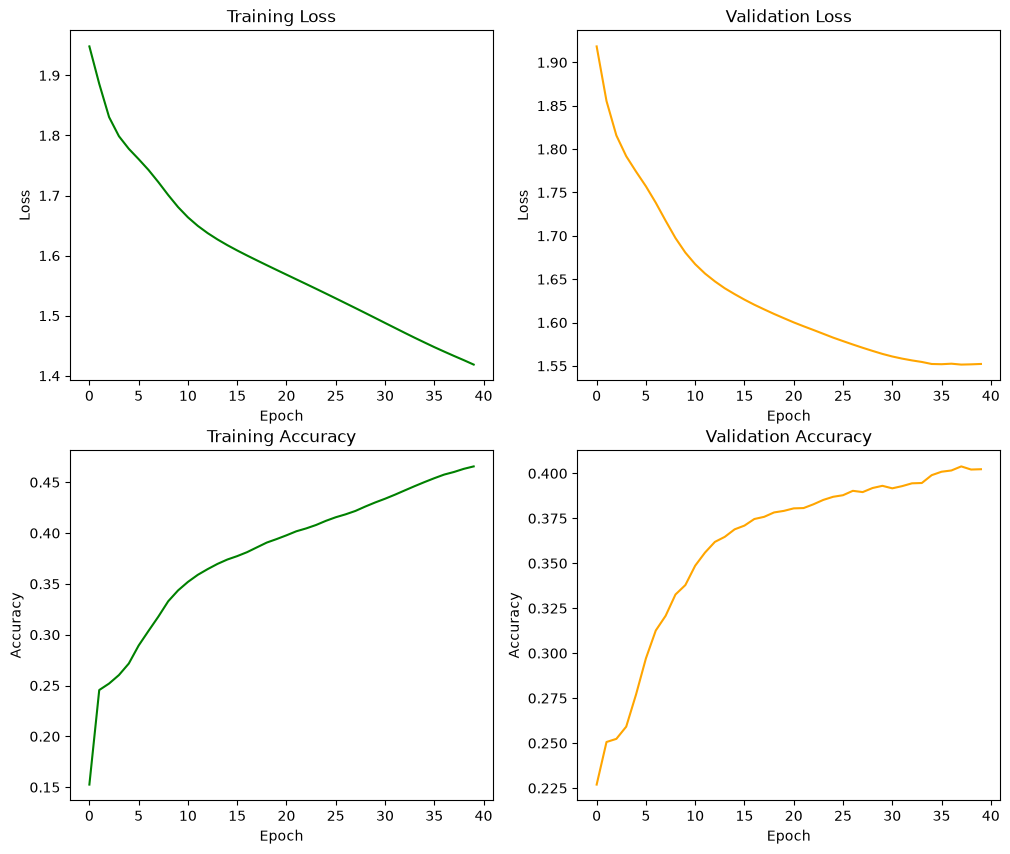

In [10]:
fig, ax = plt.subplots(2, 2, figsize=(12, 10))
ax[0, 0].plot(train_losses, color='green')
ax[0, 0].set(xlabel='Epoch', ylabel='Loss')
ax[0, 0].set_title('Training Loss')

ax[0, 1].plot(val_losses, color='orange')
ax[0, 1].set(xlabel='Epoch', ylabel='Loss')
ax[0, 1].set_title('Validation Loss')

ax[1, 0].plot(train_accs, color='green')
ax[1, 0].set(xlabel='Epoch', ylabel='Accuracy')
ax[1, 0].set_title('Training Accuracy')

ax[1, 1].plot(val_accs, color='orange')
ax[1, 1].set(xlabel='Epoch', ylabel='Accuracy')
ax[1, 1].set_title('Validation Accuracy')

plt.show()